## Import Libraries

The following libraries are used for data handling, numerical operations, and data visualization.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn:", sklearn.__version__)

## Load the Dataset

The dataset is read from the CSV file using a semicolon (`;`) as the separator.

The dataset is stored in the `dataset` folder within the project directory. A relative file path is used so the notebook can access the CSV file when the project is shared with my group members.

In [1]:
import pandas as pd

df = pd.read_csv("dataset/bank-full.csv", sep=";")

print("Dataset successfully loaded!")
print("Dataset Shape:", df.shape)

Dataset successfully loaded!
Dataset Shape: (45211, 17)


# BankReach: Bank Term Deposit Subscription Prediction Using Machine Learning

**Exploratory Data Analysis and Initial Data Preparation**

This notebook contains the problem definition, data collection, data cleaning and preprocessing, and exploratory data analysis for the BankReach project.

# 1. Problem Definition

## 1.1 Project Overview

BankReach is a machine learning project that aims to predict whether a bank customer will subscribe to a term deposit after being contacted during a marketing campaign. The project uses historical customer and campaign data from the Bank Marketing dataset.

## 1.2 Problem Type

This project is a **Binary Classification Task** because the model will predict one of two possible outcomes: whether a customer subscribed to a term deposit or not.

## 1.3 Target Variable

The target variable is `y`, which contains two possible values:

- `yes` – The customer subscribed to a term deposit.
- `no` – The customer did not subscribe to a term deposit.

## 1.4 Project Objective

The main objective is to develop and evaluate machine learning models that can predict whether a customer will subscribe to a term deposit based on available customer information and previous marketing campaign details.

The project will compare Logistic Regression and Random Forest to determine how well they perform in predicting customer subscriptions.

## 1.5 Success Metrics

The performance of the models will be measured using the following classification metrics:

- **Accuracy** – Measures the overall percentage of correct predictions.
- **Precision** – Measures how many predicted subscribers were actually subscribers.
- **Recall** – Measures how many actual subscribers were correctly identified.
- **F1-score** – Combines precision and recall into one score.
- **Confusion Matrix** – Shows the correct and incorrect predictions made by the model.

Cross-validation and hyperparameter tuning will also be used to compare and improve model performance.

Since the dataset contains more customers who did not subscribe than those who did, the project will not rely on accuracy alone. Precision, recall, and F1-score will also be considered to provide a better understanding of the models' performance, especially in identifying customers who subscribed.

# 2. Data Collection

## 2.1 Dataset Description

The dataset used in this project is the Bank Marketing dataset, specifically the `bank-full.csv` file. It contains information about customers and their interactions with a Portuguese bank's direct marketing campaigns.

The dataset consists of 45,211 records and 17 columns, including 16 input features and one target variable (`y`). It contains customer information, financial details, and marketing campaign information. It will be used to develop machine learning models that predict whether a customer will subscribe to a term deposit.

## 2.2 Dataset Source

The dataset was obtained from the UCI Machine Learning Repository.

- **Dataset Name:** Bank Marketing
- **Repository:** UCI Machine Learning Repository
- **Official Dataset Page:** https://archive.ics.uci.edu/dataset/222/bank+marketing
- **DOI:** https://doi.org/10.24432/C5K306

## 2.3 Dataset License

The Bank Marketing dataset is distributed under the Creative Commons Attribution 4.0 International (CC BY 4.0) license. This allows the dataset to be shared and adapted, provided that proper credit is given to the original source.

## 2.4 Data Retrieval Date

The dataset was downloaded on November 12, 2026.

## 2.5 Data Dictionary

The following table describes the columns included in the dataset:

| Feature | Description | Data Type |
|---|---|---|
| age | Age of the customer | Numerical |
| job | Type of job | Categorical |
| marital | Marital status of the customer (divorced includes widowed) | Categorical |
| education | Education level | Categorical |
| default | Whether the customer has credit in default | Categorical |
| balance | Average yearly account balance | Numerical |
| housing | Whether the customer has a housing loan | Categorical |
| loan | Whether the customer has a personal loan | Categorical |
| contact | Type of communication used to contact the customer | Categorical |
| day | Last contact day of the month | Numerical |
| month | Last contact month | Categorical |
| duration | Duration of the last contact in seconds | Numerical |
| campaign | Number of contacts performed during the current campaign | Numerical |
| pdays | Number of days since the customer was last contacted in a previous campaign (-1 means not previously contacted) | Numerical |
| previous | Number of contacts performed before the current campaign | Numerical |
| poutcome | Outcome of the previous marketing campaign | Categorical |
| y | Whether the customer subscribed to a term deposit (yes/no) | Binary Categorical (Target) |

**Note:** Although `duration` is included in the original dataset, it will be excluded from the main machine learning models because its value is only known after the call. Including it could cause data leakage when predicting customer subscriptions before or during marketing outreach.

## 3. Initial Dataset Inspection

In [3]:
# Display the first 5 rows
print("FIRST 5 ROWS:")
display(df.head())

# Display the last 5 rows
print("LAST 5 ROWS:")
display(df.tail())

FIRST 5 ROWS:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


LAST 5 ROWS:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


In [4]:
# Check the number of rows and columns

print("Dataset Shape:")
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape:
Number of Rows: 45211
Number of Columns: 17


In [5]:
# Display all column names
print("COLUMN NAMES:")
print(df.columns.tolist())

# Display data types
print("\nDATA TYPES:")
print(df.dtypes)

COLUMN NAMES:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

DATA TYPES:
age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object


In [6]:
# Create a data dictionary

data_dictionary = {
    "age": "Age of the customer",
    "job": "Type of job or occupation",
    "marital": "Marital status",
    "education": "Education level",
    "default": "Whether the customer has credit in default",
    "balance": "Average yearly balance in euros",
    "housing": "Whether the customer has a housing loan",
    "loan": "Whether the customer has a personal loan",
    "contact": "Type of communication contact",
    "day": "Last contact day of the month",
    "month": "Last contact month of the year",
    "duration": "Last contact duration in seconds",
    "campaign": "Number of contacts during this campaign",
    "pdays": "Number of days since the customer was last contacted (-1 means the customer was not previously contacted)",
    "previous": "Number of contacts before this campaign",
    "poutcome": "Outcome of the previous marketing campaign",
    "y": "Whether the customer subscribed to a term deposit"
}

# Display the data dictionary
for column, description in data_dictionary.items():
    print(f"{column}: {description}")

age: Age of the customer
job: Type of job or occupation
marital: Marital status
education: Education level
default: Whether the customer has credit in default
balance: Average yearly balance in euros
housing: Whether the customer has a housing loan
loan: Whether the customer has a personal loan
contact: Type of communication contact
day: Last contact day of the month
month: Last contact month of the year
duration: Last contact duration in seconds
campaign: Number of contacts during this campaign
pdays: Number of days since the customer was last contacted
previous: Number of contacts before this campaign
poutcome: Outcome of the previous marketing campaign
y: Whether the customer subscribed to a term deposit


## 4. Data Cleaning and Preprocessing

### 4.1 Duplicate and Missing Value Inspection

In [3]:


# 1. Inspect and remove duplicate rows
initial_rows = len(df)

duplicate_count = df.duplicated().sum()

print("DUPLICATE ROW INSPECTION")
print("Duplicate rows found:", duplicate_count)

df = df.drop_duplicates()

removed_rows = initial_rows - len(df)

print("Duplicate rows removed:", removed_rows)
print("Remaining duplicate rows:", df.duplicated().sum())

# 2. Inspect missing values
print("\nMISSING VALUES PER COLUMN:")
print(df.isnull().sum())

print("\nTOTAL MISSING VALUES:")
print(df.isnull().sum().sum())

# 3. Display updated dataset information
print("\nUPDATED DATASET INFORMATION")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


DUPLICATE ROW INSPECTION
Duplicate rows found: 0
Duplicate rows removed: 0
Remaining duplicate rows: 0

MISSING VALUES PER COLUMN:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

TOTAL MISSING VALUES:
0

UPDATED DATASET INFORMATION
Number of rows: 45211
Number of columns: 17


Interpretation

The dataset was checked for duplicate rows and missing values. The inspection found no duplicate records and no missing values in any of the 17 columns. Since the dataset is already complete and contains no exact duplicate rows, no additional cleaning was needed for these two checks. The dataset still contains 45,211 rows and 17 columns after the inspection.

In [3]:
# Check unknown values in categorical columns

categorical_columns = df.select_dtypes(include=["str"]).columns

for column in categorical_columns:
    unknown_count = (df[column] == "unknown").sum()

    if unknown_count > 0:
        print(f"{column}: {unknown_count} unknown values")

job: 288 unknown values
education: 1857 unknown values
contact: 13020 unknown values
poutcome: 36959 unknown values


### Checking Unknown Values

The dataset was checked for unknown values in its categorical columns. The results showed that four columns contain values labeled as "unknown":

- job: 288 unknown values
- education: 1,857 unknown values
- contact: 13,020 unknown values
- poutcome: 36,959 unknown values

These values represent information that was not available or recorded in the original dataset. They are different from missing values because they are explicitly stored as the category "unknown".

For this project, these values will be retained instead of being immediately deleted or replaced. One-Hot Encoding will be used later to handle categorical features, including their unknown categories.

In [4]:
# Inspect outliers in numerical columns using the IQR method

numerical_columns = df.select_dtypes(include="number").columns

outlier_summary = []

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ).sum()

    outlier_summary.append({
        "Feature": column,
        "Outlier Count": outlier_count,
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)

display(outlier_df)

,Feature,Outlier Count,Lower Bound,Upper Bound
0,age,487,10.5,70.5
1,balance,4729,-1962.0,3462.0
2,day,0,-11.5,40.5
3,duration,3235,-221.0,643.0
4,campaign,3064,-2.0,6.0
5,pdays,8257,-1.0,-1.0
6,previous,8257,0.0,0.0


### 4.2 Data Type Inspection

In [4]:
#INSPECT DATA TYPES


print("DATA TYPES OF EACH COLUMN:")
print(df.dtypes)

print("\nDATASET INFORMATION:")
df.info()

DATA TYPES OF EACH COLUMN:
age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object

DATASET INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 

# Interpretation

The data types of all 17 columns were inspected. The dataset contains 7 numerical columns with integer data types and 10 categorical columns with string data types. All columns have 45,211 non-null values. Based on the inspection, the current data types are appropriate, so no corrections are needed at this stage. The categorical columns will be converted into numerical formats later during feature engineering.

# Set the visual style for EDA charts
sns.set_theme(style="whitegrid")

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style
sns.set_theme(style="whitegrid")

print("Visualization libraries are ready!")

Visualization libraries are ready!


### 5.1 Bank Term Deposit Subscription Distribution

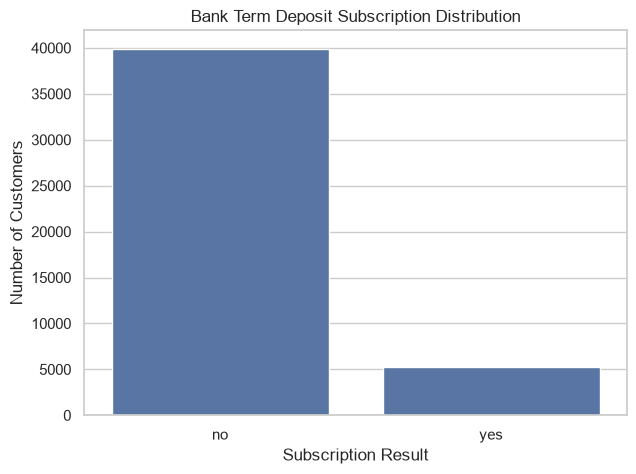

SUBSCRIPTION COUNTS:
y
no     39922
yes     5289
Name: count, dtype: int64

SUBSCRIPTION PERCENTAGES:
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


In [6]:
# Target Distribution

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='y')

plt.title('Bank Term Deposit Subscription Distribution')
plt.xlabel('Subscription Result')
plt.ylabel('Number of Customers')

plt.show()

# Display counts and percentages
print("SUBSCRIPTION COUNTS:")
print(df['y'].value_counts())

print("\nSUBSCRIPTION PERCENTAGES:")
print(df['y'].value_counts(normalize=True) * 100)

# Interpretation

The chart shows that most customers did not subscribe to a bank term deposit. Out of 45,211 customers, 39,922 (88.30%) did not subscribe, while only 5,289 (11.70%) subscribed. This shows that our dataset is imbalanced because the number of customers who did not subscribe is much higher than those who did. This is important to consider when training and evaluating our machine learning models because accuracy alone may not be enough to measure model performance.

### 5.2 Age Distribution of Bank Customers

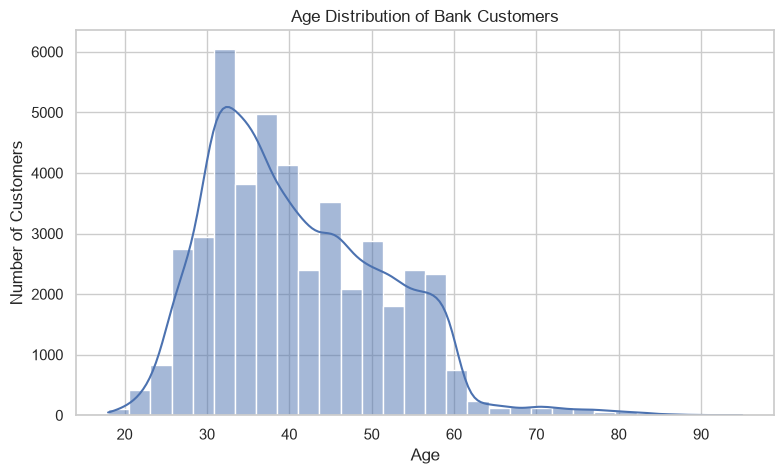

AGE SUMMARY:
count    45211.000000
mean        40.936210
std         10.618762
min         18.000000
25%         33.000000
50%         39.000000
75%         48.000000
max         95.000000
Name: age, dtype: float64


In [7]:
# Age Distribution

plt.figure(figsize=(9, 5))

sns.histplot(data=df, x='age', bins=30, kde=True)

plt.title('Age Distribution of Bank Customers')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()

print("AGE SUMMARY:")
print(df['age'].describe())

# Interpretation

The histogram shows that most bank customers are between their late 20s and late 50s, with the highest number of customers around the early 30s. Based on the summary statistics, the average customer age is approximately 41 years, while the median age is 39 years. The youngest customer is 18 years old, and the oldest is 95 years old. This shows that the dataset includes customers from different age groups, but most of them are middle-aged adults.

### 5.3 Customer Distribution by Job

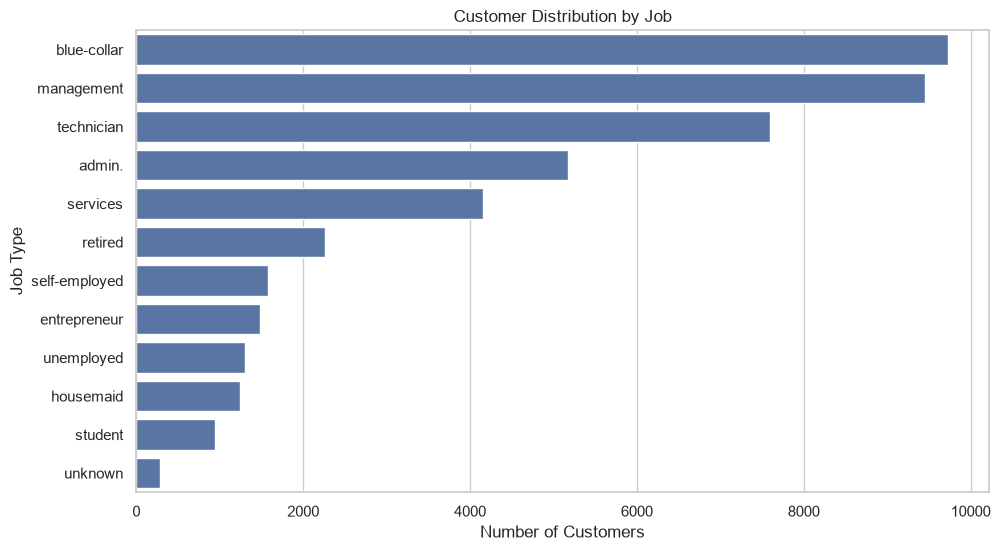

CUSTOMER COUNT BY JOB:
job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64


In [8]:
# Customer Distribution by Job

plt.figure(figsize=(11, 6))

sns.countplot(
    data=df,
    y='job',
    order=df['job'].value_counts().index
)

plt.title('Customer Distribution by Job')
plt.xlabel('Number of Customers')
plt.ylabel('Job Type')

plt.show()

print("CUSTOMER COUNT BY JOB:")
print(df['job'].value_counts())

# Interpretation

The chart shows the distribution of customers according to their job types. Blue-collar workers have the highest number of customers with 9,732, followed closely by management employees with 9,458. Technicians are also well represented, with 7,597 customers. On the other hand, the unknown job category has the lowest count, with only 288 customers. This shows that blue-collar, management, and technician workers make up a large portion of the bank's customer records.

### 5.4 Term Deposit Subscription by Job Type

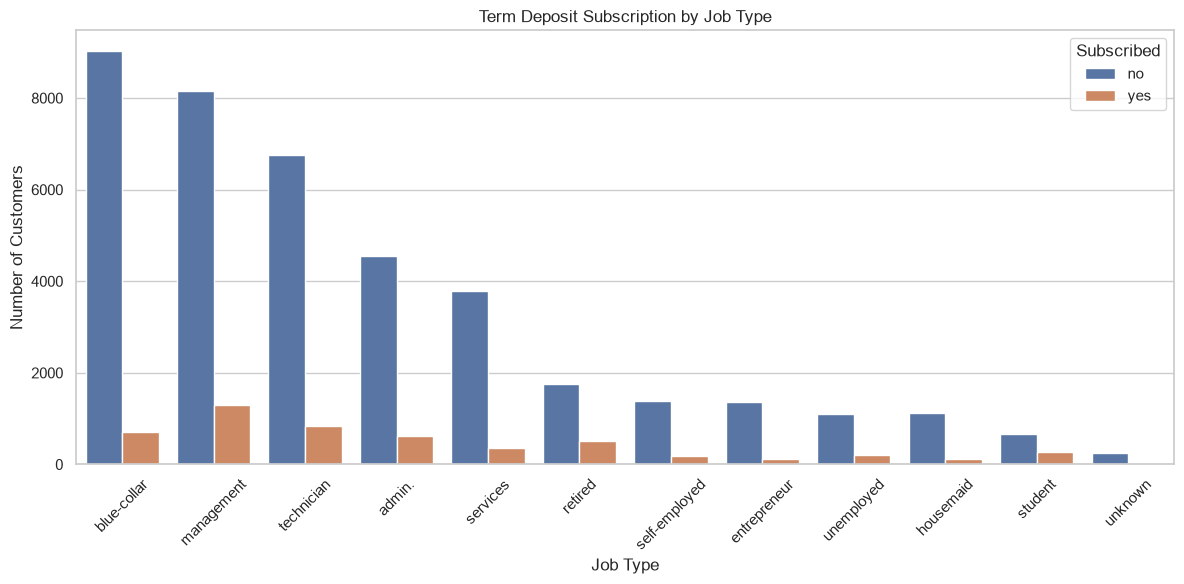

In [9]:
# Subscription Results by Job

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='job',
    hue='y',
    order=df['job'].value_counts().index
)

plt.title('Term Deposit Subscription by Job Type')
plt.xlabel('Job Type')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)
plt.legend(title='Subscribed')

plt.tight_layout()
plt.show()

# Interpretation

The chart compares the number of customers who subscribed and did not subscribe to a term deposit across different job categories. Management employees have the highest number of subscribers, followed by technicians and blue-collar workers. However, blue-collar workers have the highest total number of customers, with most of them not subscribing. The chart also shows that non-subscribers outnumber subscribers in every job category. This helps us understand how subscription results are distributed across different occupations.

### 5.5 Distribution of Customer Account Balances

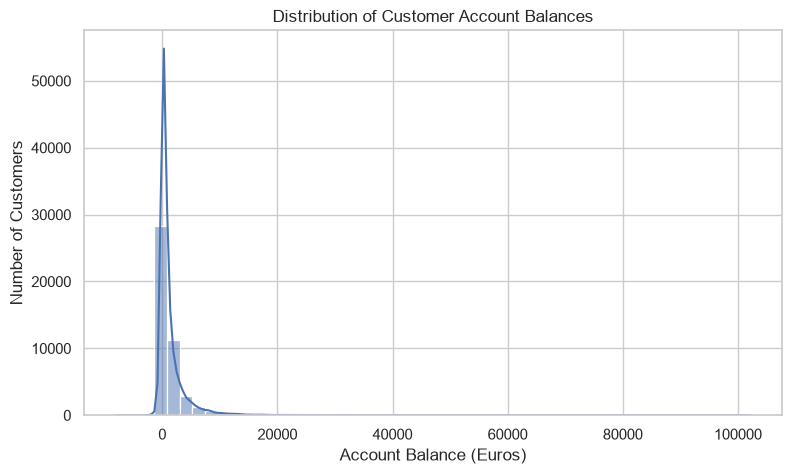

BALANCE SUMMARY:
count     45211.000000
mean       1362.272058
std        3044.765829
min       -8019.000000
25%          72.000000
50%         448.000000
75%        1428.000000
max      102127.000000
Name: balance, dtype: float64


In [10]:
# Balance Distribution

plt.figure(figsize=(9, 5))

sns.histplot(data=df, x='balance', bins=50, kde=True)

plt.title('Distribution of Customer Account Balances')
plt.xlabel('Account Balance (Euros)')
plt.ylabel('Number of Customers')

plt.show()

print("BALANCE SUMMARY:")
print(df['balance'].describe())

# Interpretation

The histogram shows that most customers have account balances concentrated around the lower values, while only a small number have very high balances. The average balance is approximately €1,362.27, which is higher than the median of €448. This suggests that some customers with high balances increase the overall average. The dataset also contains negative balances, with the lowest being -€8,019, while the highest balance reaches €102,127. Overall, the distribution is highly right-skewed, meaning that most customers have lower balances and only a few have much higher balances.

### 5.6 Term Deposit Subscription Rate by Age Group

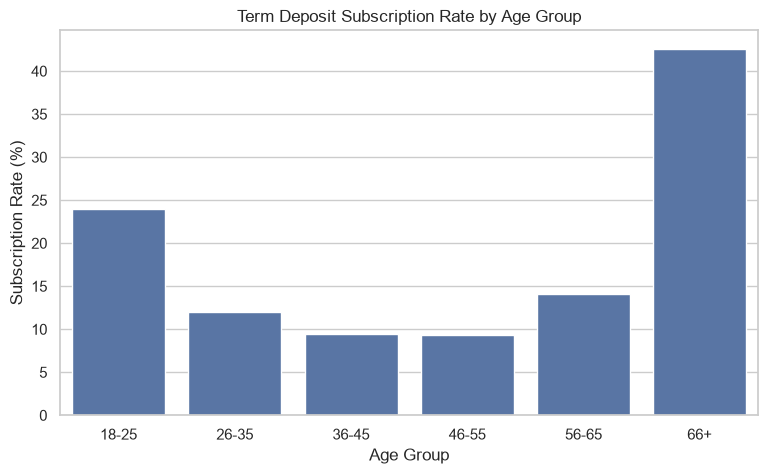

  Age Group  Subscription Rate
0     18-25          23.952096
1     26-35          12.003083
2     36-45           9.389434
3     46-55           9.352744
4     56-65          14.123885
5       66+          42.609854


In [11]:


# Subscription Rate by Age Group

df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=['18-25', '26-35', '36-45', '46-55', '56-65', '66+']
)

age_subscription = df.groupby(
    'age_group', observed=False
)['y'].apply(lambda x: (x == 'yes').mean() * 100).reset_index()

age_subscription.columns = ['Age Group', 'Subscription Rate']

plt.figure(figsize=(9, 5))

sns.barplot(
    data=age_subscription,
    x='Age Group',
    y='Subscription Rate'
)

plt.title('Term Deposit Subscription Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Subscription Rate (%)')

plt.show()

print(age_subscription)


# Interpretation

The chart shows the percentage of customers who subscribed to a term deposit across different age groups. Customers aged 66 and above have the highest subscription rate at 42.61%, followed by those aged 18–25 at 23.95%. Meanwhile, customers aged 36–45 and 46–55 have the lowest subscription rates, at 9.39% and 9.35%. This shows that subscription rates vary across age groups, with older customers aged 66 and above having a noticeably higher rate of subscription in this dataset.

### 5.7 Correlation Heatmap of Numerical Variables

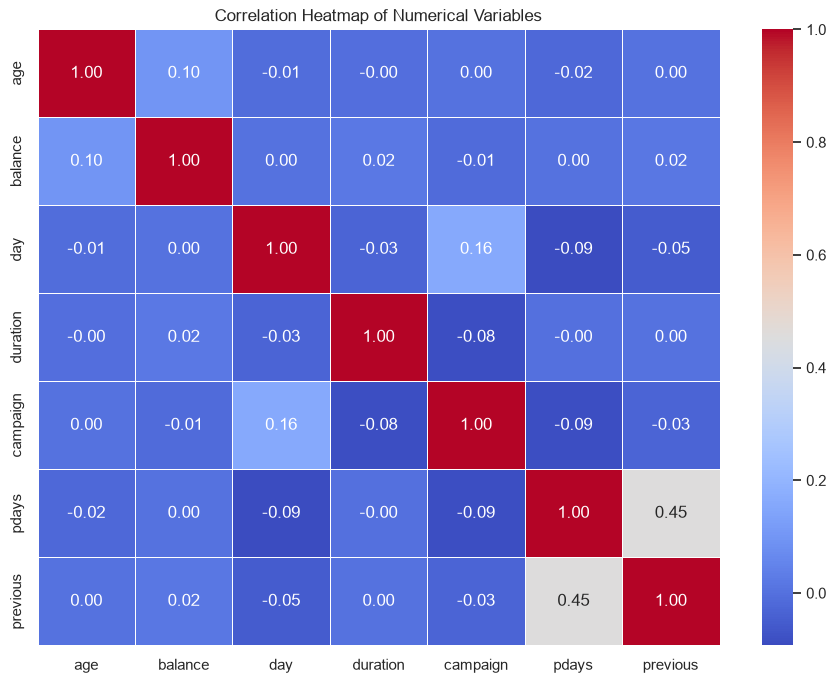

In [13]:
# Correlation Heatmap

numerical_df = df.select_dtypes(include=['int64'])

correlation_matrix = numerical_df.corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Variables')

plt.show()


# Interpretation

The correlation heatmap shows the relationships between the numerical variables in the dataset. Most variables have weak or very weak correlations with one another. The strongest positive relationship is between `pdays` and `previous`, with a correlation value of 0.45. This suggests that customers who were contacted more in previous campaigns may also have higher values for the number of days since their last contact. The relationship between `day` and `campaign` is also positive but weak, with a value of 0.16. Overall, the heatmap shows that most numerical variables do not have strong linear relationships with each other.

## 6. EDA Summary

The visualizations show the distribution of the target variable and several customer characteristics. The target variable is imbalanced, with substantially more customers who did not subscribe than customers who subscribed. Age-group subscription rates also vary, and the numerical correlation heatmap shows that most pairs of numerical variables have weak linear relationships.

These findings will be considered during feature engineering, model selection, and model evaluation.